In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# HARQ x Kuo-helper study: requested analyses (2026-10-22)

All figures requested in the session, in order:
1. How the distance is defined (code + trace check)
2. Roundabout traces: curve-only KPI window, validation renders (W exit, E exit)
3. R1 PRR vs distance, highway vs roundabout curve, moderate background (periodic / aperiodic)
4. R1 vs R4 PRR vs distance on the highway, moderate background (periodic / aperiodic)
5. R1 vs R2 vs R3 PRR vs distance, periodic, moderate background: highway / roundabout curve
6. Commands (remote restart, local seed-1 run)

PRR vs distance uses per-packet data (`_pkt.csv[.gz]`: one row per packet x member, `dist_m` = actual
leader-member distance at the first attempt, from the ns-3 mobility model fed by the SUMO trace), binned in 35 m
bins. The curves are a **non-linear (logistic) regression** weighted by the packets per bin:

$$\mathrm{PRR}(d) = b + \frac{a - b}{1 + e^{(d - d_{50})/w}}$$

$a$ = plateau PRR at short range, $b$ = floor at long range, $d_{50}$ = distance of the mid-point between $a$ and
$b$, $w$ = width of the drop (m).
Re-run `python3 build_requests_notebook.py --hwy-profile full --rbt-profile full` when the full results are in.

In [1]:
import glob, gzip, os, sys, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import Image, display
HERE = '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study'
sys.path.insert(0, HERE)
import study
HWY_PROF, RBT_PROF = 'remote_v3', 'remote_v3'
ARMS_PROF = {'hwy': 'remote_v3', 'rbt': 'remote_v3', 'rbtE': 'remote_v3'}
GAP = 35.0                                   # IVD 30 m + vehicle length 5 m
EDGES = np.arange(GAP / 2, 280 + GAP, GAP)   # bins centred on 35, 70, ..., 280 m
MIN_PKTS = 30
CURVE_TOL = 0.5
plt.rcParams['figure.dpi'] = 110


def load_pkt(prof, arm, scen, traf, bg='moderate'):
    pre = {f.split('_pkt.csv')[0] for f in
           glob.glob(f'{HERE}/out/{prof}/{arm}/{scen}_ivd30_{traf}_{bg}_s*_pkt.csv*')}
    fs = [p + '_pkt.csv' if os.path.exists(p + '_pkt.csv') else p + '_pkt.csv.gz' for p in sorted(pre)]
    if not fs:
        return None, 0
    p = pd.concat(pd.read_csv(f) for f in fs)
    return p[p.dist_m >= 0], len(fs)


def curve_only(p):
    # roundabout: keep packets whose leader-member link bends on the ring
    return p[p.dist_m < p.member * GAP - CURVE_TOL]


def binned(p):
    g = p.assign(bin=pd.cut(p.dist_m, EDGES)).groupby('bin', observed=True).agg(
        d=('dist_m', 'mean'), prr=('rx', 'mean'), n=('rx', 'size'))
    return g[g.n >= MIN_PKTS]


def logistic(d, a, b, d50, w):
    return b + (a - b) / (1 + np.exp((d - d50) / w))


def fit(g):
    """weighted logistic fit (sigma ~ binomial std of each bin); returns params or None"""
    sig = np.sqrt(np.clip(g.prr * (1 - g.prr), 0.01, None) / g.n)
    try:
        p, _ = curve_fit(logistic, g.d, g.prr, p0=[g.prr.max(), min(g.prr.min(), 0.5) * 0.5, g.d.median(), 50.0],
                         sigma=sig, bounds=([0, 0, 0, 1], [1, 1, 5000, 2000]), maxfev=50000)
        return p
    except Exception as e:
        print('fit failed:', e)
        return None


def plot_curves(ax, series, ylim=(0, 1.02)):
    """series: list of (label, color, binned df)"""
    rows = []
    for lab, col, g in series:
        if g is None or g.empty:
            continue
        ax.plot(g.d, g.prr, 'o', color=col, alpha=.45, ms=5)
        p = fit(g)
        if p is not None:
            xs = np.linspace(g.d.min(), g.d.max(), 200)
            ax.plot(xs, logistic(xs, *p), '-', color=col, lw=2,
                    label=f'{lab}: a={p[0]:.2f}, b={p[1]:.2f}, d50={p[2]:.0f} m, w={p[3]:.0f} m')
            rows.append(dict(series=lab, a=p[0], b=p[1], d50_m=p[2], w_m=p[3],
                             rmse=np.sqrt(np.mean((logistic(g.d, *p) - g.prr) ** 2))))
        else:
            ax.plot(g.d, g.prr, '-', color=col, label=lab)
    ax.set_xlabel('leader-member distance (m)'); ax.set_ylabel('PRR')
    ax.set_ylim(*ylim); ax.grid(alpha=.3); ax.legend(fontsize=7)
    return pd.DataFrame(rows)

## 1. Distance definition

Question: is the distance computed from member index x IVD, or from the actual SUMO positions?

Answer: actual positions. `platoon_harq_robustness_eval.cc` `OnPlatoonPsschTx` (~l. 580) stores
`a->GetDistanceFrom(b)` (transmitter -> member, ns-3 `WaypointMobilityModel` driven by the trace) for every
transmission; each packet keeps the value at its first attempt (`dist_m` in `_pkt.csv`), and `mean_dist_m`
in `_member.csv` is its mean over packets. The `local1` roundabout runs (`--maxTime=20`) only covered the straight
northern approach, where the platoon keeps the exact arc-length gap, hence exactly 35, 70, ..., 280 m.

In [2]:
tr = f'{study.EVAL}/traces/rbt_ivd30_n60_s1.csv.gz'
d = pd.read_csv(tr, comment='#'); d.columns = ['t', 'node', 'x', 'y', 'v']
p = d[d.node <= 8].pivot_table(index='t', columns='node', values=['x', 'y'])
rows = []
for t in range(0, 66, 5):
    i = p.index[np.argmin(abs(p.index - t))]
    rows.append({'t': t, 'leader_x': p.x[0][i], 'leader_y': p.y[0][i],
                 **{f'd_m{m}': np.hypot(p.x[m][i] - p.x[0][i], p.y[m][i] - p.y[0][i]) for m in (1, 4, 8)}})
pd.DataFrame(rows).round(1)

,t,leader_x,leader_y,d_m1,d_m4,d_m8
0,0,-4.8,326.2,35.0,140.0,280.0
1,5,-4.8,255.6,35.0,140.0,280.0
2,10,-4.8,185.0,35.0,140.0,280.0
3,15,-4.8,122.0,35.0,140.0,280.0
4,20,-4.8,84.9,35.0,140.0,280.0
5,25,-4.8,61.3,35.0,140.0,280.0
6,30,-5.9,30.4,34.8,139.8,279.8
7,35,-31.2,5.5,35.0,131.8,270.5
8,40,-88.9,4.8,35.0,110.7,228.1
9,45,-153.6,4.8,35.0,133.5,209.4


## 2. Roundabout: curve-only KPI window and trace validation

`study.curve_window(trace)`: from the first sample where any leader-member link bends (straight distance
< member x 35 m - 0.5 m, i.e. the leader enters the ring) to the last one (the tail leaves the curve), +/- 1 s;
the `full` profile passes it as `--kpiStart` / `--maxTime` (maxTime includes the 0.3 s tail guard).
Two routes from the northern arm: `rbt` = west exit (1/4 of the ring), `rbtE` = east exit (3/4 of the ring,
`gen_mobility.py --rbt-exit E`).

In [3]:
rows = []
for pre in ('rbt', 'rbtE'):
    for n in (0, 60):
        for s in range(1, 11):
            tr = f'{study.EVAL}/traces/{pre}_ivd30_n{n}_s{s}.csv.gz'
            if os.path.exists(tr):
                k0, tm = study.curve_window(tr)
                rows.append(dict(route=pre, nbg=n, seed=s, kpiStart=k0, kpiEnd=round(tm - study.TAIL_GUARD, 1),
                                 window_s=round(tm - study.TAIL_GUARD - k0, 1)))
W = pd.DataFrame(rows)
display(W.pivot_table(index=['route', 'nbg'], values='window_s', aggfunc=['min', 'mean', 'max']).round(1))
W

min     mean      max
          window_s window_s window_s
route nbg                           
rbt   0       20.0     25.5     27.0
      60      24.9     27.5     29.6
rbtE  0       27.6     35.7     37.9
      60      34.8     37.7     42.8

,route,nbg,seed,kpiStart,kpiEnd,window_s
0,rbt,0,1,21.0,47.6,26.6
1,rbt,0,2,21.2,48.0,26.8
2,rbt,0,3,21.1,47.9,26.8
3,rbt,0,4,21.0,47.5,26.5
4,rbt,0,5,21.1,47.8,26.7
5,rbt,0,6,21.3,48.3,27.0
6,rbt,0,7,19.4,44.1,24.7
7,rbt,0,8,19.6,44.5,24.9
8,rbt,0,9,15.7,35.7,20.0
9,rbt,0,10,19.5,44.3,24.8


Renders of the trace over the SUMO net + buildings (red = inside the KPI window, star = leader). Generated by `render_rbt_trace.py`.

rbt_ivd30_n60_s1


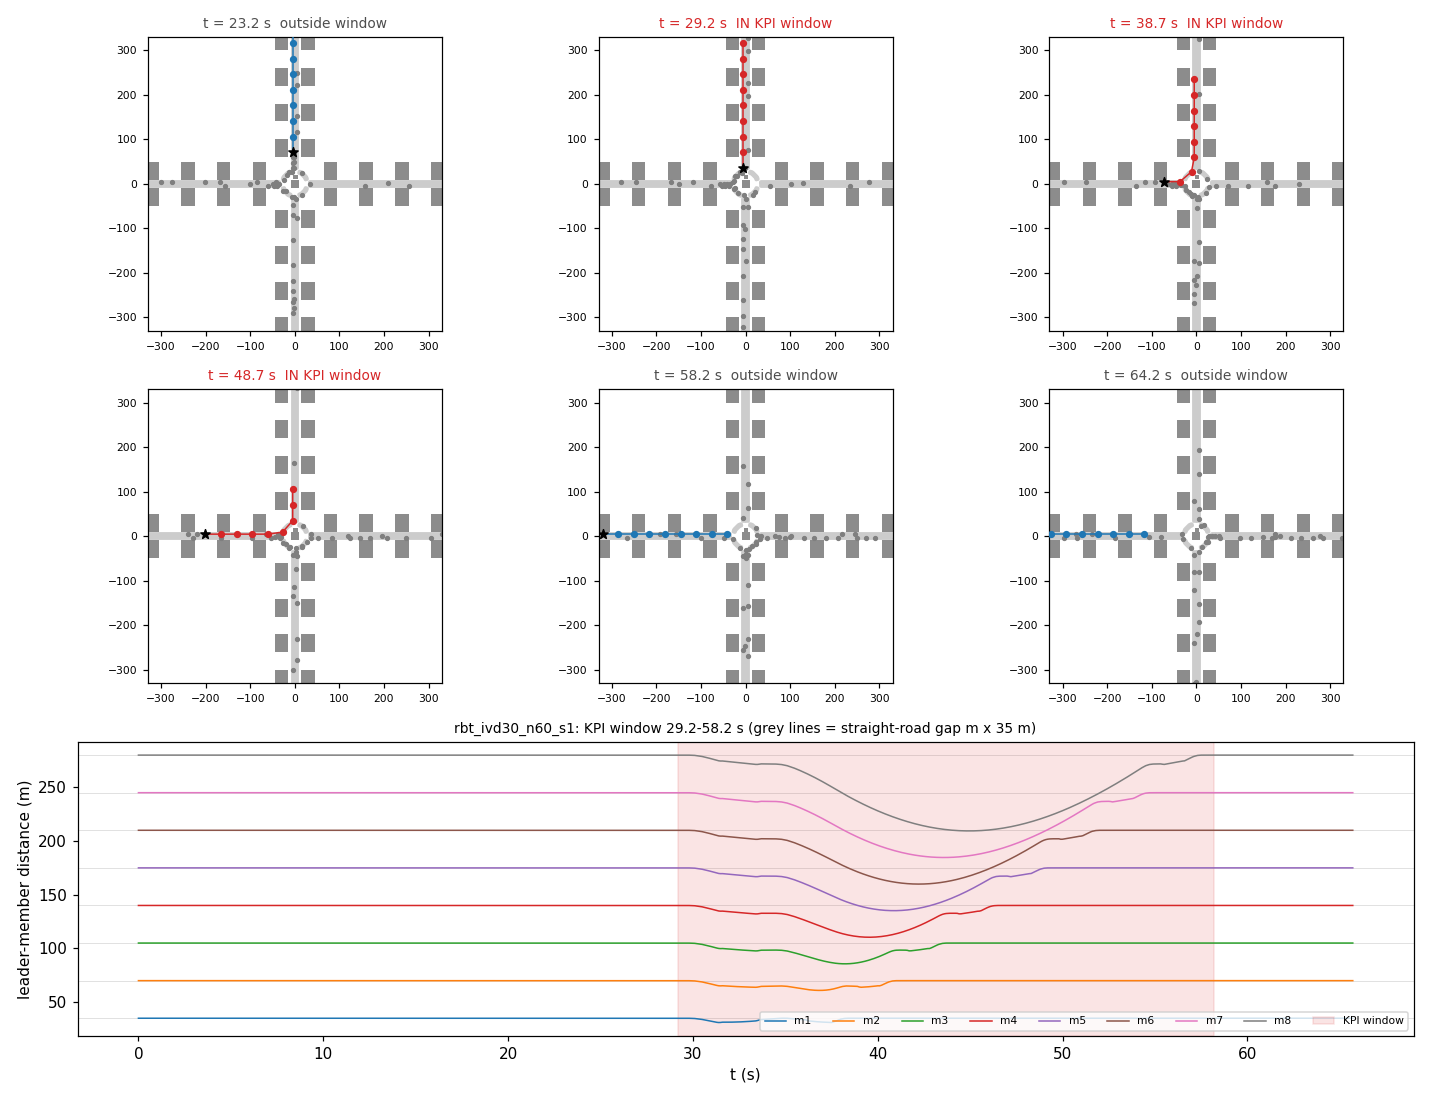

rbt_ivd30_n60_s5


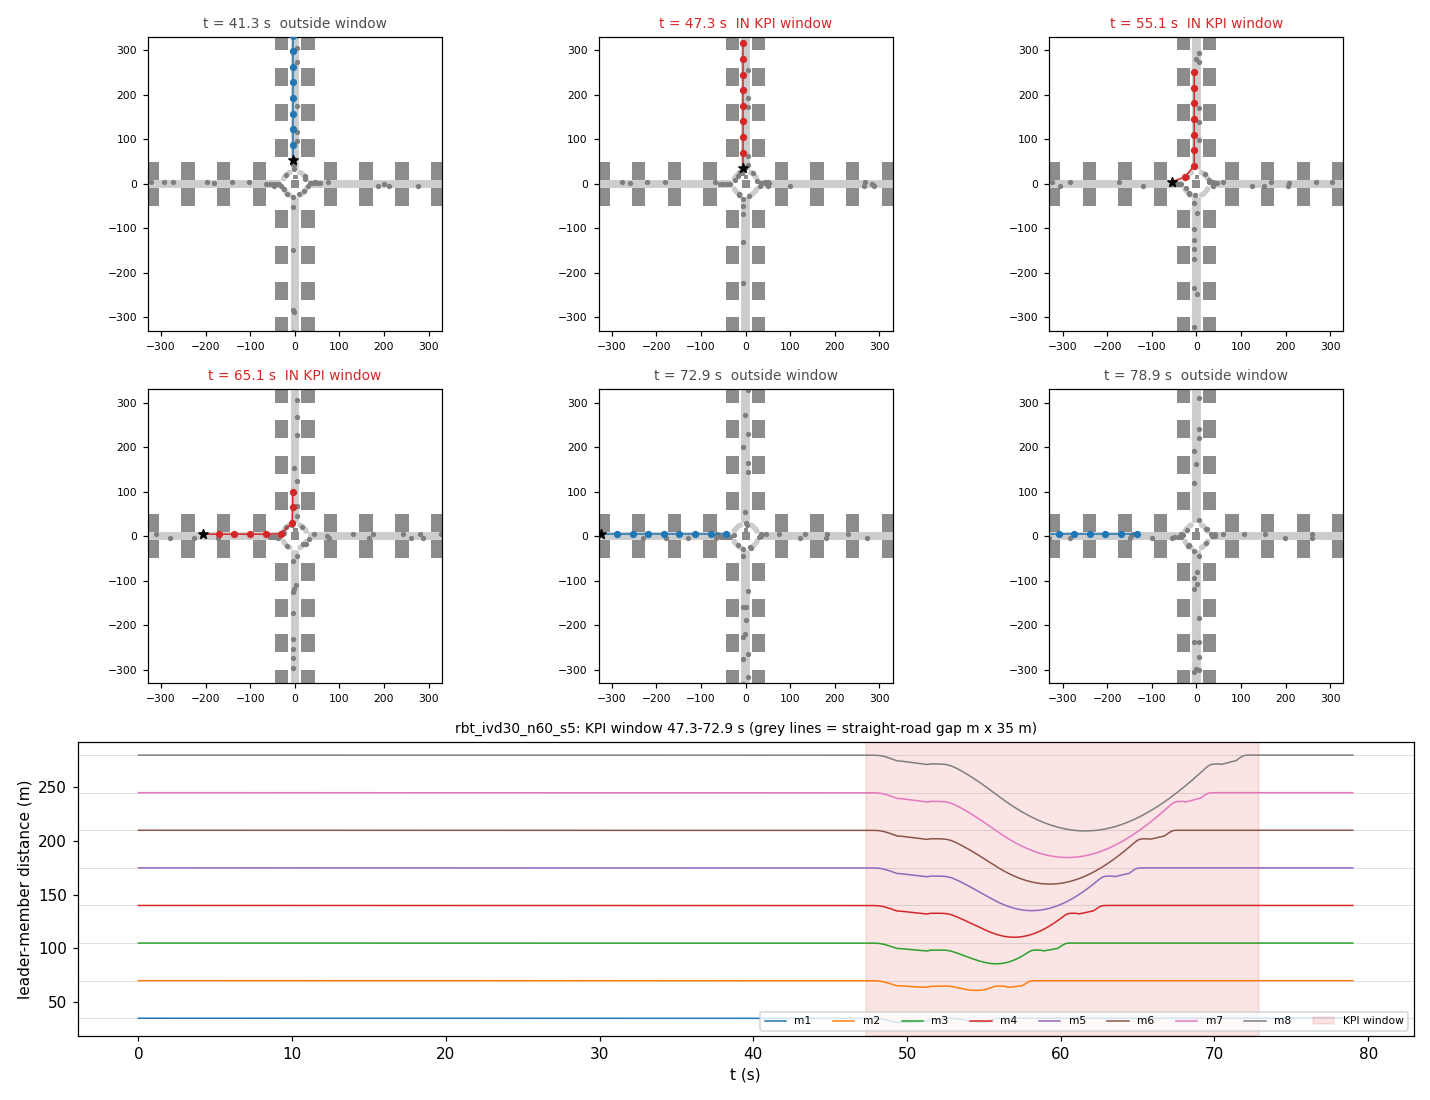

rbtE_ivd30_n60_s1


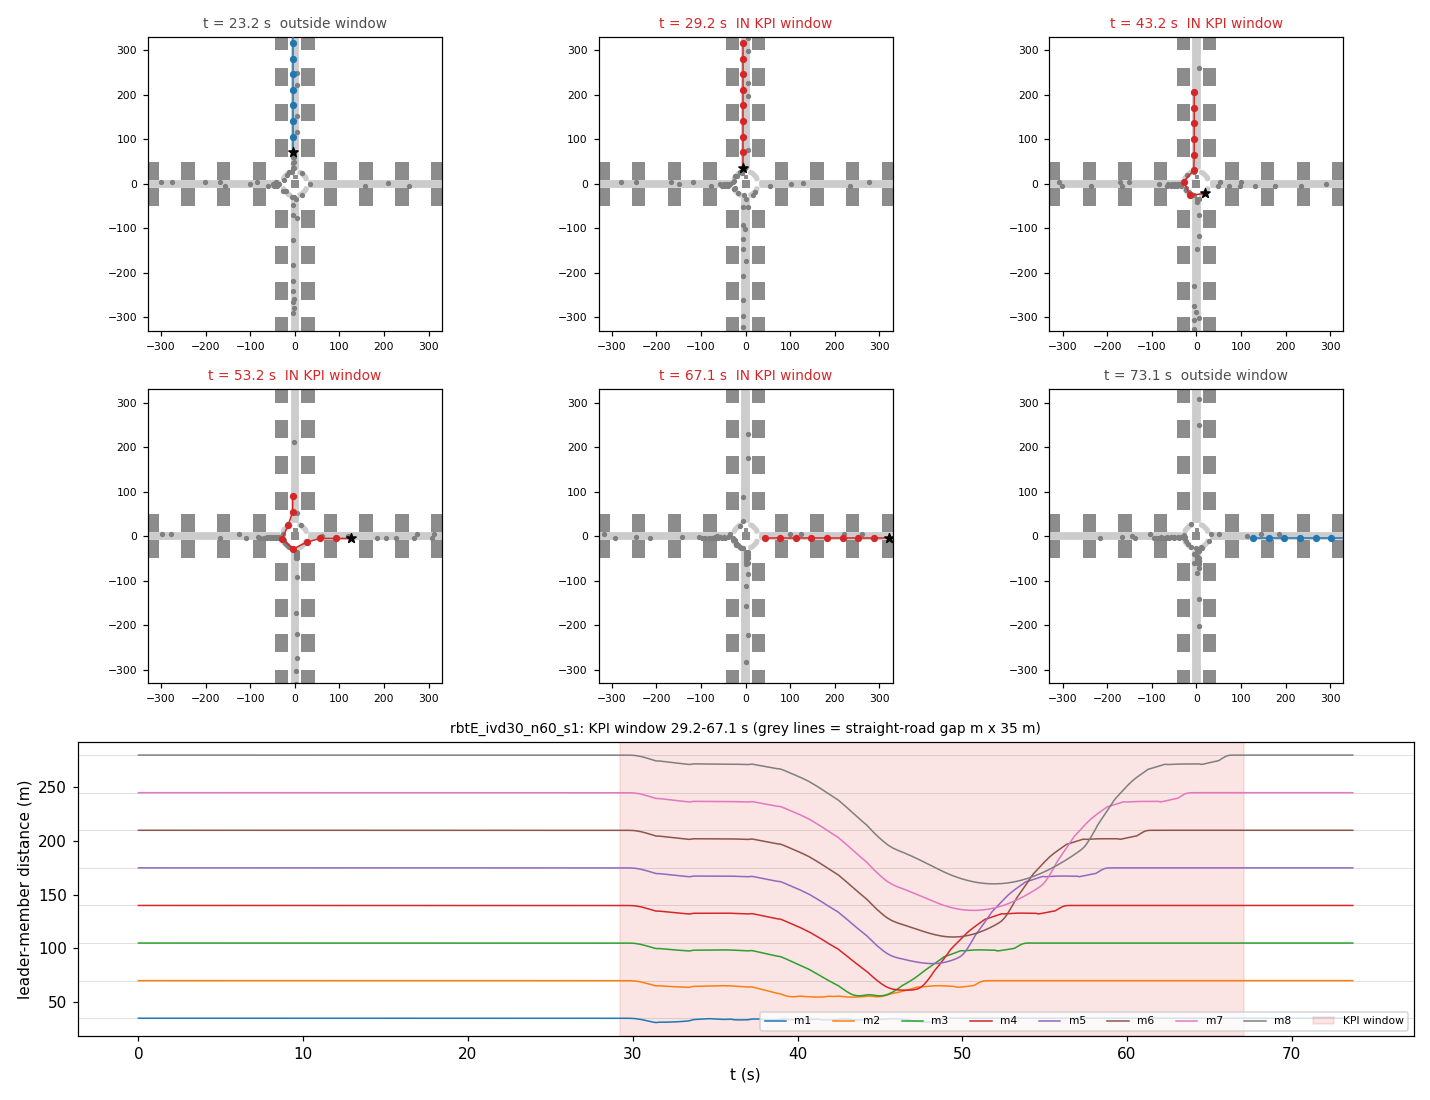

In [4]:
for name in ('rbt_ivd30_n60_s1', 'rbt_ivd30_n60_s5', 'rbtE_ivd30_n60_s1'):
    png = f'{HERE}/figures/trace_{name}_snapshots.png'
    if not os.path.exists(png):
        subprocess.run([sys.executable, f'{HERE}/render_rbt_trace.py', name], check=True)
    print(name); display(Image(png))

rbt_ivd30_n60_s1


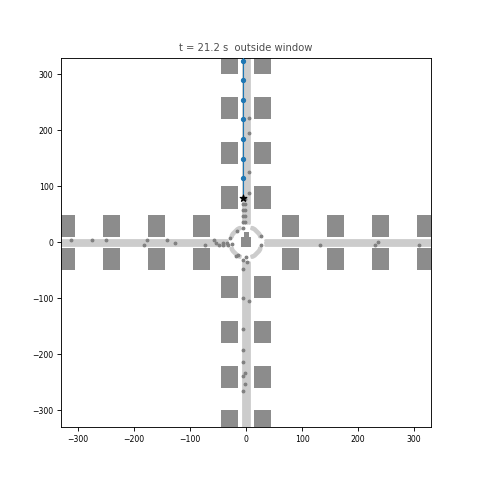

rbtE_ivd30_n60_s1


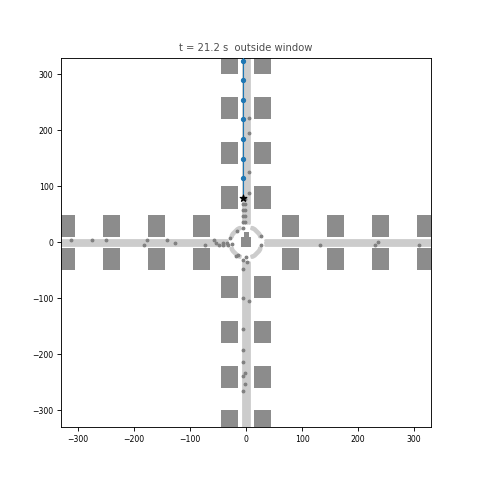

In [5]:
# animations (W exit, E exit)
for name in ('rbt_ivd30_n60_s1', 'rbtE_ivd30_n60_s1'):
    print(name); display(Image(f'{HERE}/figures/trace_{name}.gif'))

## 3. R1 PRR vs distance: highway vs roundabout curve (moderate background)

Highway: all packets (`HWY_PROF`). Roundabout: curve only (`RBT_PROF`, curve KPI window + bent-link filter);
the E-exit route is added when its runs exist.

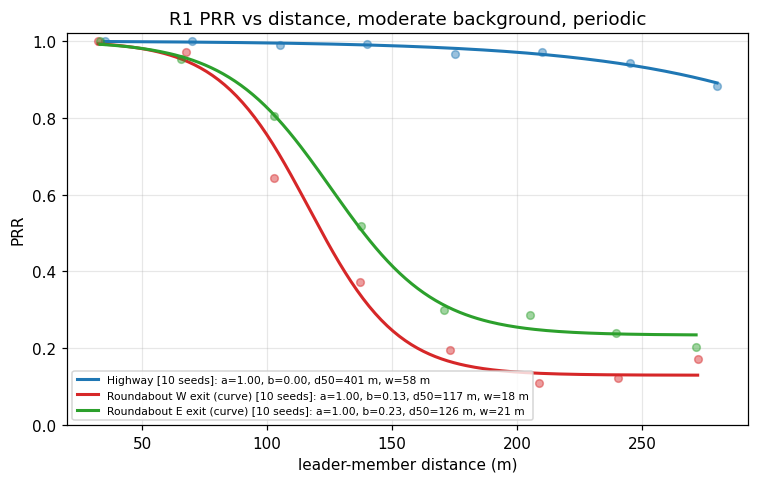

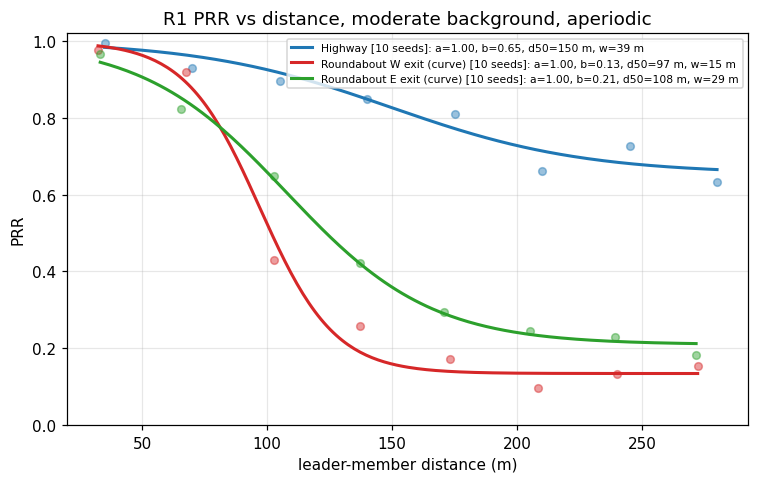

,traffic,series,a,b,d50_m,w_m,rmse
0,periodic1tb,Highway [10 seeds],1.000,0.000,400.721,57.594,0.007
1,periodic1tb,Roundabout W exit (curve) [10 seeds],1.000,0.130,116.739,17.859,0.039
2,periodic1tb,Roundabout E exit (curve) [10 seeds],1.000,0.234,125.506,20.820,0.018
0,aperiodic1tb,Highway [10 seeds],1.000,0.654,149.623,38.574,0.034
1,aperiodic1tb,Roundabout W exit (curve) [10 seeds],0.999,0.134,97.061,15.010,0.038
2,aperiodic1tb,Roundabout E exit (curve) [10 seeds],1.000,0.210,107.914,28.929,0.018


In [6]:
fits = []
for traf in ('periodic1tb', 'aperiodic1tb'):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ser = []
    for scen, prof, lab, col, curve in [('hwy', HWY_PROF, 'Highway', 'C0', False),
                                        ('rbt', RBT_PROF, 'Roundabout W exit (curve)', 'C3', True),
                                        ('rbtE', RBT_PROF, 'Roundabout E exit (curve)', 'C2', True)]:
        p, ns = load_pkt(prof, 'R1', scen, traf)
        if p is None:
            print(f'no data: R1 {scen} {traf} ({prof})'); continue
        ser.append((f'{lab} [{ns} seed{"s" * (ns > 1)}]', col, binned(curve_only(p) if curve else p)))
    f = plot_curves(ax, ser); f.insert(0, 'traffic', traf); fits.append(f)
    ax.set_title(f'R1 PRR vs distance, moderate background, {traf.replace("1tb", "")}')
    fig.tight_layout(); fig.savefig(f'{HERE}/figures/r1_prr_dist_{traf.replace("1tb", "")}.png', dpi=150); plt.show()
pd.concat(fits).round(3)

## 4. R1 vs R4 PRR vs distance, highway, moderate background

R1 = leader only, blind; R4 = Kuo helper, blind. Periodic y-axis zoomed to 0.75-1.

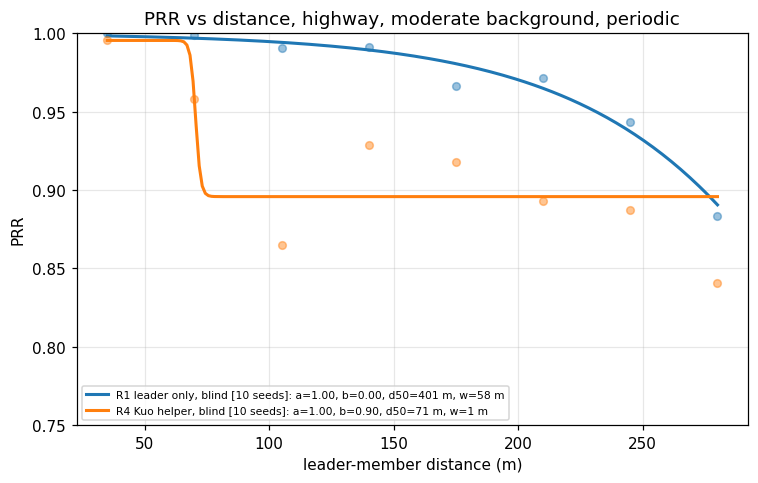

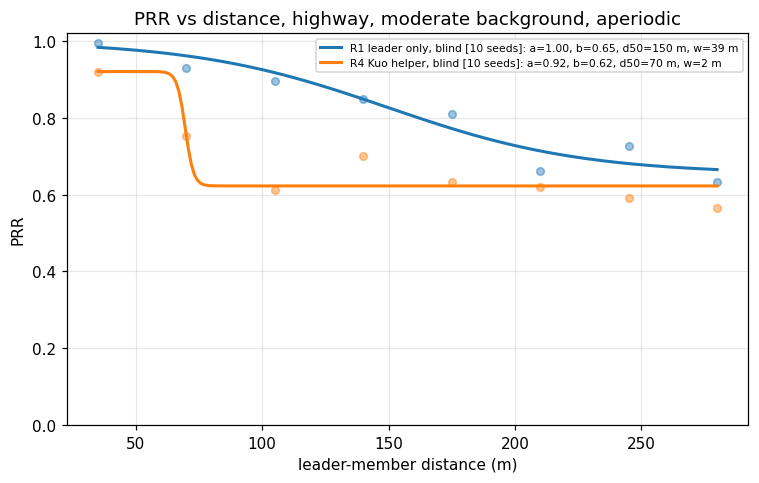

,traffic,series,a,b,d50_m,w_m,rmse
0,periodic1tb,"R1 leader only, blind [10 seeds]",1.000,0.000,400.721,57.594,0.007
1,periodic1tb,"R4 Kuo helper, blind [10 seeds]",0.995,0.896,70.520,1.007,0.027
0,aperiodic1tb,"R1 leader only, blind [10 seeds]",1.000,0.654,149.623,38.574,0.034
1,aperiodic1tb,"R4 Kuo helper, blind [10 seeds]",0.920,0.622,69.559,1.625,0.037


In [7]:
fits = []
for traf in ('periodic1tb', 'aperiodic1tb'):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ser = []
    for arm, lab, col in [('R1', 'R1 leader only, blind', 'C0'), ('R4', 'R4 Kuo helper, blind', 'C1')]:
        p, ns = load_pkt(HWY_PROF, arm, 'hwy', traf)
        if p is None:
            print(f'no data: {arm} {traf}'); continue
        ser.append((f'{lab} [{ns} seed{"s" * (ns > 1)}]', col, binned(p)))
    f = plot_curves(ax, ser, ylim=(0.75, 1.0) if traf == 'periodic1tb' else (0, 1.02))
    f.insert(0, 'traffic', traf); fits.append(f)
    ax.set_title(f'PRR vs distance, highway, moderate background, {traf.replace("1tb", "")}')
    fig.tight_layout()
    fig.savefig(f'{HERE}/figures/prr_dist_R1_R4_hwy_moderate_{traf.replace("1tb", "")}_{HWY_PROF}.png', dpi=150)
    plt.show()
pd.concat(fits).round(3)

## 5. R1 vs R2 vs R3 PRR vs distance, periodic traffic, moderate background

R1 = leader blind, R2 = leader HARQ Option 1, R3 = leader HARQ Option 2. Data: `ARMS_PROF` per scenario
(local: highway `local1` = 20 s seed 1, all arms same run length; roundabout `full` = curve window, seed 1). Highway: all packets; roundabout: curve only (W exit `rbt`; E exit `rbtE` in a third plot when
present). Only runs whose command has the curve window are used for the roundabout.

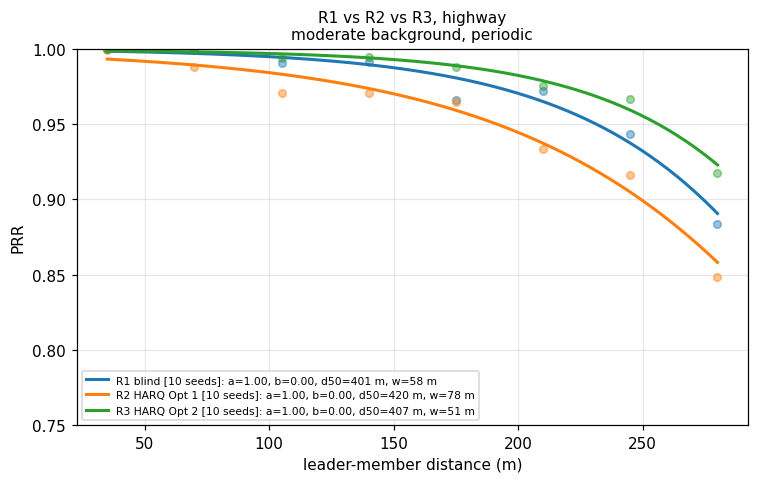

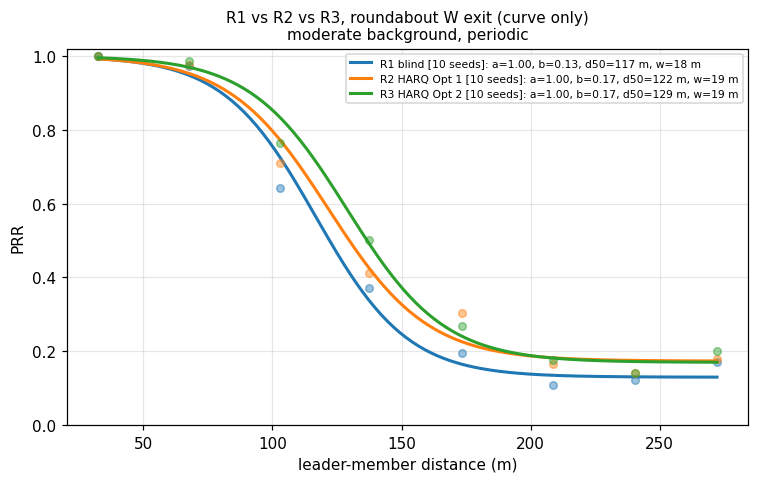

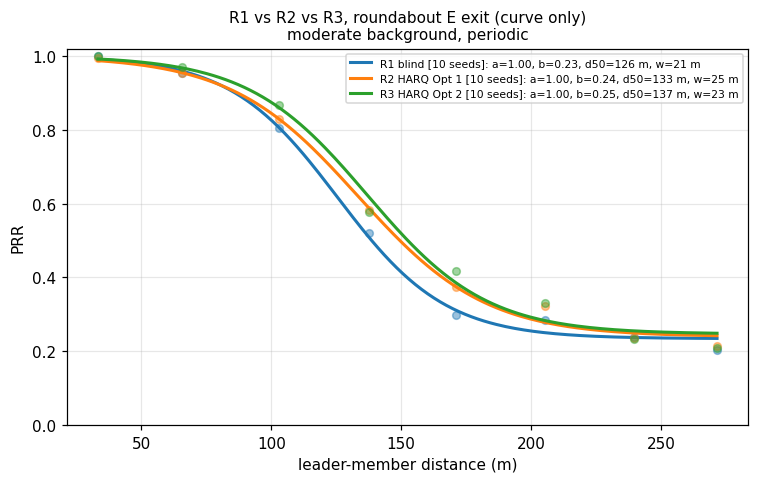

,scenario,series,a,b,d50_m,w_m,rmse
0,hwy,R1 blind [10 seeds],1.000,0.000,400.721,57.594,0.007
1,hwy,R2 HARQ Opt 1 [10 seeds],1.000,0.000,419.582,77.568,0.008
2,hwy,R3 HARQ Opt 2 [10 seeds],0.999,0.000,407.449,51.154,0.004
0,rbt,R1 blind [10 seeds],1.000,0.130,116.739,17.859,0.039
1,rbt,R2 HARQ Opt 1 [10 seeds],1.000,0.174,121.555,19.250,0.039
2,rbt,R3 HARQ Opt 2 [10 seeds],1.000,0.170,128.858,18.766,0.031
0,rbtE,R1 blind [10 seeds],1.000,0.234,125.506,20.820,0.018
1,rbtE,R2 HARQ Opt 1 [10 seeds],1.000,0.240,133.471,24.598,0.020
2,rbtE,R3 HARQ Opt 2 [10 seeds],1.000,0.247,136.954,22.972,0.030


In [8]:
import json
def load_pkt_curve(prof, arm, scen, traf, bg='moderate'):
    # roundabout: only runs made with the curve window (--kpiStart in the command), curve packets only
    keep, old = [], 0
    for m in sorted(glob.glob(f'{HERE}/out/{prof}/{arm}/{scen}_ivd30_{traf}_{bg}_s*.cmd.json')):
        pre = m[:-len('.cmd.json')]
        if not any(c.startswith('--kpiStart') for c in json.load(open(m))):
            old += 1; continue
        f = pre + '_pkt.csv' if os.path.exists(pre + '_pkt.csv') else pre + '_pkt.csv.gz'
        if os.path.exists(f):
            keep.append(f)
    if old:
        print(f'{arm} {scen}: {old} run(s) without the curve window ignored')
    if not keep:
        return None, 0
    p = pd.concat(pd.read_csv(f) for f in keep)
    return curve_only(p[p.dist_m >= 0]), len(keep)

fits = []
traf = 'periodic1tb'
for scen, title, curve in [('hwy', 'highway', False), ('rbt', 'roundabout W exit (curve only)', True),
                           ('rbtE', 'roundabout E exit (curve only)', True)]:
    ser = []
    for arm, lab, col in [('R1', 'R1 blind', 'C0'), ('R2', 'R2 HARQ Opt 1', 'C1'), ('R3', 'R3 HARQ Opt 2', 'C2')]:
        p, ns = (load_pkt_curve if curve else load_pkt)(ARMS_PROF[scen], arm, scen, traf)
        if p is None:
            print(f'no data: {arm} {scen} ({ARMS_PROF[scen]})'); continue
        ser.append((f'{lab} [{ns} seed{"s" * (ns > 1)}]', col, binned(p)))
    if not ser:
        continue
    fig, ax = plt.subplots(figsize=(7, 4.5))
    lo = min(g.prr.min() for _, _, g in ser if not g.empty)
    f = plot_curves(ax, ser, ylim=(np.floor(lo * 20) / 20 - 0.05, 1.0) if lo > 0.6 else (0, 1.02))  # zoom if all high
    f.insert(0, 'scenario', scen); fits.append(f)
    ax.set_title(f'R1 vs R2 vs R3, {title}\nmoderate background, periodic', fontsize=10)
    fig.tight_layout(); fig.savefig(f'{HERE}/figures/prr_dist_R1_R2_R3_{scen}_moderate_periodic.png', dpi=150)
    plt.show()
pd.concat(fits).round(3) if fits else None

## 6. Commands

Remote (from `harq_helper_study/`), stop the running study, then pull + restart (resumable: highway runs are
skipped, roundabout runs re-done with the curve window, `rbtE` traces generated if missing, needs SUMO):
```bash
./launch_full.sh --stop
./launch_full.sh --pull coop-arms --no-smoke --seeds 1-5 --jobs 8
grep -L kpiStart out/full/*/rbt*.cmd.json      # empty = every roundabout run has the curve window
```
Local seed 1, moderate background, main arms (36 runs, ~9 h at 2 jobs):
```bash
nohup python3 study.py run --profile full --seeds 1 --jobs 2 --only '^R[1-6]/.*_moderate_s1$' > out/full_s1_run.log 2>&1 &
python3 build_requests_notebook.py --hwy-profile full --rbt-profile full
```
Trace validation: `python3 render_rbt_trace.py rbtE_ivd30_n60_s1`.